In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# Load data
train = pd.read_csv("/content/train.csv")

# Feature engineering
data = train.copy()

# Total passenger expenditure
spending_columns = [
    "RoomService",
    "FoodCourt",
    "ShoppingMall",
    "Spa",
    "VRDeck"
]

data["TotalSpend"] = data[spending_columns].sum(
    axis=1, min_count=1
)

# Passenger group size
data["GroupId"] = (
    data["PassengerId"].astype(str).str.split("_").str[0]
)

group_sizes = data["GroupId"].value_counts()

data["GroupSize"] = data["GroupId"].map(group_sizes)

# Remove identifiers and target from predictors
X = data.drop(
    columns=[
        "Transported",
        "PassengerId",
        "Name",
        "Cabin",
        "GroupId"
    ]
)

y = data["Transported"].astype(int)

# Identify numerical and categorical variables
numeric_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

# Preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

# Model
model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", HistGradientBoostingClassifier(
        max_iter=150,
        learning_rate=0.08,
        max_leaf_nodes=15,
        random_state=42
    ))
])

# Validation split
X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Train
model.fit(X_train, y_train)

# Predict
predictions = model.predict(X_valid)

# Evaluate
results = {
    "Model": "HistGradientBoosting",
    "Accuracy": accuracy_score(y_valid, predictions),
    "Precision": precision_score(y_valid, predictions),
    "Recall": recall_score(y_valid, predictions),
    "F1": f1_score(y_valid, predictions)
}

print("MODEL EXPERIMENT RESULTS")
display(pd.DataFrame([results]).round(4))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_valid, predictions))

MODEL EXPERIMENT RESULTS


,Model,Accuracy,Precision,Recall,F1
0,HistGradientBoosting,0.7999,0.7839,0.8322,0.8073



CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0       0.82      0.77      0.79       863
           1       0.78      0.83      0.81       876

    accuracy                           0.80      1739
   macro avg       0.80      0.80      0.80      1739
weighted avg       0.80      0.80      0.80      1739



In [2]:
experiment_results = pd.DataFrame([results])

experiment_results.to_csv(
    "/content/additional_model_experiments.csv",
    index=False
)

print("Experiment results saved.")

Experiment results saved.


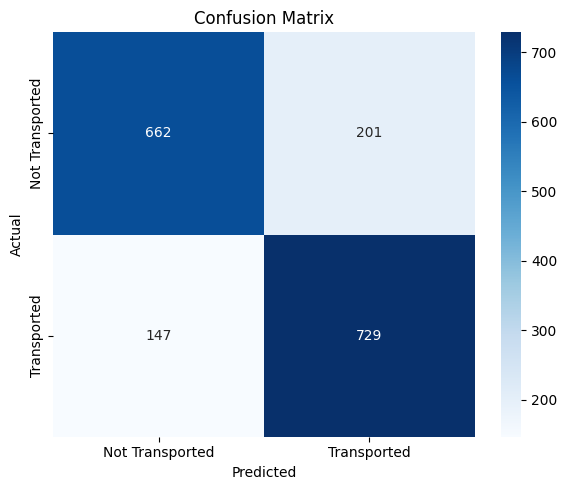

Total misclassified passengers: 348

Error types:


,count
Error Type,
False Positive,201
False Negative,147



Misclassified passenger characteristics:


,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,TotalSpend,GroupSize,Actual,Predicted,Error Type
7173,Earth,True,TRAPPIST-1e,4.0,False,0.0,0.0,0.0,0.0,0.0,0.0,5,0,1,False Positive
1683,Earth,True,PSO J318.5-22,21.0,False,0.0,0.0,0.0,NaN,0.0,0.0,2,0,1,False Positive
3695,Earth,True,TRAPPIST-1e,17.0,False,0.0,0.0,0.0,0.0,0.0,0.0,1,0,1,False Positive
4834,Earth,NaN,TRAPPIST-1e,40.0,False,814.0,12.0,2.0,NaN,79.0,907.0,1,1,0,False Negative
1881,Europa,False,TRAPPIST-1e,31.0,False,0.0,0.0,0.0,0.0,0.0,0.0,3,0,1,False Positive
2812,Earth,True,TRAPPIST-1e,4.0,False,0.0,0.0,0.0,0.0,0.0,0.0,4,0,1,False Positive
3581,Europa,False,TRAPPIST-1e,57.0,False,205.0,4415.0,0.0,1589.0,305.0,6514.0,1,0,1,False Positive
2483,Earth,False,55 Cancri e,13.0,False,0.0,0.0,0.0,4.0,811.0,815.0,1,1,0,False Negative
3114,Earth,False,TRAPPIST-1e,32.0,False,0.0,810.0,0.0,0.0,2.0,812.0,1,0,1,False Positive
1866,Earth,False,TRAPPIST-1e,22.0,False,213.0,85.0,352.0,12.0,1.0,663.0,2,1,0,False Negative



Error analysis completed.


In [3]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Confusion matrix
cm = confusion_matrix(y_valid, predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Transported", "Transported"],
    yticklabels=["Not Transported", "Transported"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(
    "/content/confusion_matrix.png",
    dpi=300
)
plt.show()

# Identify incorrectly classified passengers
errors = X_valid.copy()

errors["Actual"] = y_valid
errors["Predicted"] = predictions

errors["Error Type"] = np.where(
    (errors["Actual"] == 0) & (errors["Predicted"] == 1),
    "False Positive",
    "False Negative"
)

errors = errors[
    errors["Actual"] != errors["Predicted"]
]

print("Total misclassified passengers:", len(errors))

print("\nError types:")
display(errors["Error Type"].value_counts())

print("\nMisclassified passenger characteristics:")
display(errors.head(20))

errors.to_csv(
    "/content/validation_errors.csv",
    index=False
)

print("\nError analysis completed.")

In [4]:
experiment_results = pd.DataFrame([results])

experiment_results.to_csv(
    "/content/additional_model_experiments.csv",
    index=False
)

print("Experiment results saved.")

Experiment results saved.


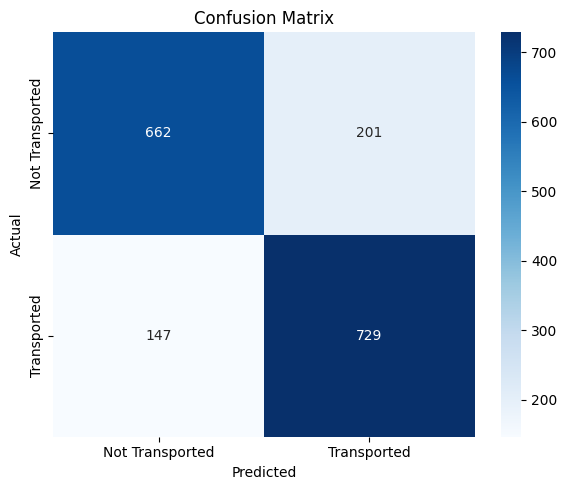

Total misclassified passengers: 348

Error types:


,count
Error Type,
False Positive,201
False Negative,147



Misclassified passenger characteristics:


,HomePlanet,CryoSleep,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,TotalSpend,GroupSize,Actual,Predicted,Error Type
7173,Earth,True,TRAPPIST-1e,4.0,False,0.0,0.0,0.0,0.0,0.0,0.0,5,0,1,False Positive
1683,Earth,True,PSO J318.5-22,21.0,False,0.0,0.0,0.0,NaN,0.0,0.0,2,0,1,False Positive
3695,Earth,True,TRAPPIST-1e,17.0,False,0.0,0.0,0.0,0.0,0.0,0.0,1,0,1,False Positive
4834,Earth,NaN,TRAPPIST-1e,40.0,False,814.0,12.0,2.0,NaN,79.0,907.0,1,1,0,False Negative
1881,Europa,False,TRAPPIST-1e,31.0,False,0.0,0.0,0.0,0.0,0.0,0.0,3,0,1,False Positive
2812,Earth,True,TRAPPIST-1e,4.0,False,0.0,0.0,0.0,0.0,0.0,0.0,4,0,1,False Positive
3581,Europa,False,TRAPPIST-1e,57.0,False,205.0,4415.0,0.0,1589.0,305.0,6514.0,1,0,1,False Positive
2483,Earth,False,55 Cancri e,13.0,False,0.0,0.0,0.0,4.0,811.0,815.0,1,1,0,False Negative
3114,Earth,False,TRAPPIST-1e,32.0,False,0.0,810.0,0.0,0.0,2.0,812.0,1,0,1,False Positive
1866,Earth,False,TRAPPIST-1e,22.0,False,213.0,85.0,352.0,12.0,1.0,663.0,2,1,0,False Negative



Error analysis completed.


In [5]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Confusion matrix
cm = confusion_matrix(y_valid, predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Not Transported", "Transported"],
    yticklabels=["Not Transported", "Transported"]
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig(
    "/content/confusion_matrix.png",
    dpi=300
)
plt.show()

# Identify incorrectly classified passengers
errors = X_valid.copy()

errors["Actual"] = y_valid
errors["Predicted"] = predictions

errors["Error Type"] = np.where(
    (errors["Actual"] == 0) & (errors["Predicted"] == 1),
    "False Positive",
    "False Negative"
)

errors = errors[
    errors["Actual"] != errors["Predicted"]
]

print("Total misclassified passengers:", len(errors))

print("\nError types:")
display(errors["Error Type"].value_counts())

print("\nMisclassified passenger characteristics:")
display(errors.head(20))

errors.to_csv(
    "/content/validation_errors.csv",
    index=False
)

print("\nError analysis completed.")